# Neural network: one hidden layer

Run in order: **Data → Model → Training → Evaluation → Visualization**.

Fit noisy observations of $y=\sin(\pi x)$ using **32 ReLU hidden units**.

Requires `torch` and `matplotlib`. This small example runs on a CPU; no dataset download is needed.

## 1. Data

Generate **80 training** and **40 validation** observations independently:
$$x\sim\mathrm{Uniform}(-1,1),\qquad y=\sin(\pi x)+\epsilon,\qquad \epsilon\sim\mathcal N(0,0.1^2).$$

Store observations in rows: inputs and targets both have shape $(N,1)$.

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

# ============================================================
# 1. Generate data
# ============================================================
torch.manual_seed(0)

N_train, N_val = 80, 40
noise_std = 0.1
batch_size = 16


def make_data(n):
    x = 2 * torch.rand(n, 1) - 1
    y = torch.sin(math.pi * x) + noise_std * torch.randn(n, 1)
    return x, y


x_train, y_train = make_data(N_train)
x_val, y_val = make_data(N_val)
x_grid = torch.linspace(-1, 1, 401).reshape(-1, 1)
y_true = torch.sin(math.pi * x_grid)

train_loader = DataLoader(
    TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(0),
)

print(f"Training: {tuple(x_train.shape)}, validation: {tuple(x_val.shape)}")
print(f"Batch size: {batch_size}; updates per epoch: {len(train_loader)}")

Training: (80, 1), validation: (40, 1)
Batch size: 16; updates per epoch: 5


### View the dataset

The dashed curve is the noise-free function used to generate the observations.

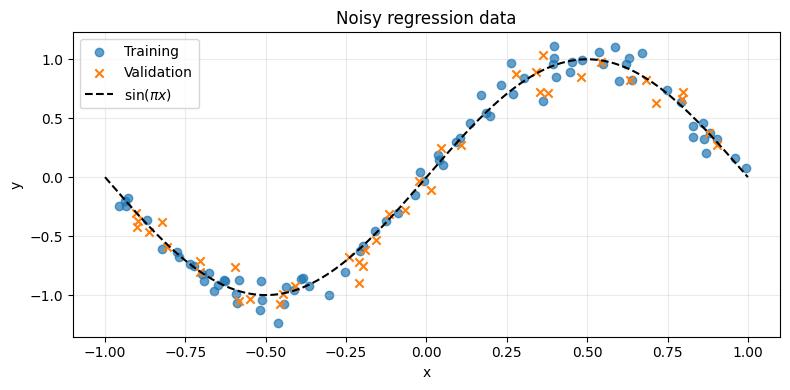

In [2]:
plt.figure(figsize=(8, 4))
plt.scatter(x_train[:, 0], y_train[:, 0], label="Training", alpha=0.7)
plt.scatter(x_val[:, 0], y_val[:, 0], label="Validation", marker="x", color="tab:orange")
plt.plot(x_grid[:, 0], y_true[:, 0], "k--", label=r"$\sin(\pi x)$")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy regression data")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 2. Model

Each hidden unit applies a nonlinear activation:
$$h_j(x)=\mathrm{ReLU}(w_j^{(1)}x+b_j^{(1)}),\qquad \mathrm{ReLU}(a)=\max(0,a).$$
The output is a weighted sum:
$$f(x)=b^{(2)}+\sum_{j=1}^{M}w_j^{(2)}h_j(x).$$

For a batch stored in rows:
$$H=\mathrm{ReLU}(XW_1+b_1),\qquad F=HW_2+b_2.$$

| Tensor | Shape |
|---|---|
| $X$ | $B\times1$ |
| $W_1$, $b_1$ | $1\times M$, $M$ |
| $H$ | $B\times M$ |
| $W_2$, $b_2$ | $M\times1$, $1$ |
| $F$ | $B\times1$ |

Biases broadcast across rows. Row-wise storage transposes the column-vector convention in the lecture.

Minimize mean squared error (MSE):
$$\mathcal L(\theta)=\frac1N\sum_{n=1}^{N}(f(x_n;\theta)-y_n)^2.$$

Initialize hidden units with different random weights; all four parameter tensors are trainable.

In [3]:
# ============================================================
# 2. Define and initialize the network
# ============================================================
M = 32

# Input dimension is 1; use different random weights for each unit.
w1 = torch.randn(1, M).requires_grad_()
b1 = torch.zeros(M, requires_grad=True)
w2 = (torch.randn(M, 1) / math.sqrt(M)).requires_grad_()
b2 = torch.zeros(1, requires_grad=True)
parameters = [w1, b1, w2, b2]


def forward(x):
    h = torch.relu(x @ w1 + b1)
    f = h @ w2 + b2
    return f


def compute_loss(x, y):
    return torch.mean((forward(x) - y) ** 2)


# Check the batch shapes from the slide.
x_batch, y_batch = next(iter(train_loader))
with torch.no_grad():
    h_batch = torch.relu(x_batch @ w1 + b1)
    f_batch = forward(x_batch)
    initial_prediction = forward(x_grid).clone()

for name, tensor in [("X", x_batch), ("W1", w1), ("b1", b1),
                     ("H", h_batch), ("W2", w2), ("b2", b2), ("F", f_batch)]:
    print(f"{name:>2}: {tuple(tensor.shape)}")

# Keep the same starting point for the torch.nn implementation below.
initial_parameters = [p.detach().clone() for p in parameters]

 X: (16, 1)
W1: (1, 32)
b1: (32,)
 H: (16, 32)
W2: (32, 1)
b2: (1,)
 F: (16, 1)


### Automatic differentiation with PyTorch

Use a small network to inspect the chain rule:
$$a=wx+b,\quad h=\mathrm{ReLU}(a),\quad f=vh+c,\quad \ell=(f-y)^2.$$

For $x=2$, $y=1$, $w=0.5$, $b=-0.5$, $v=-1$, $c=0$:
$$a=h=0.5,\quad f=-0.5,\quad \ell=2.25.$$

Starting from the loss:
$$\frac{\partial\ell}{\partial f}=2(f-y)=-3,\qquad
\frac{\partial\ell}{\partial a}=\frac{\partial\ell}{\partial f}\,v\,\mathbf1_{a>0}=3.$$
Thus $\partial\ell/\partial w=3x=6$ and $\partial\ell/\partial b=3$.

PyTorch records the operations in the forward pass. **One `backward()` call applies the chain rule** to compute every gradient. `retain_grad()` lets us also inspect intermediate tensors.

**Step 1 — Mark the parameters.**

`requires_grad=True` tells PyTorch to track operations involving a tensor. The input and target are fixed here, so they do not need gradients.

In [4]:
# Separate scalar example; this does not change the 32-unit model.
ad_x = torch.tensor(2.0)
ad_y = torch.tensor(1.0)
ad_w = torch.tensor(0.5, requires_grad=True)
ad_b = torch.tensor(-0.5, requires_grad=True)
ad_v = torch.tensor(-1.0, requires_grad=True)
ad_c = torch.tensor(0.0, requires_grad=True)

print("Track gradients for w:", ad_w.requires_grad)
print("w.grad before backward:", ad_w.grad)  # None: not computed yet.

Track gradients for w: True
w.grad before backward: None


**Step 2 — Run the forward pass.**

PyTorch records each operation and its dependencies in a **computation graph**. An intermediate tensor's `grad_fn` identifies the backward operation PyTorch will use. We write only the forward calculation; PyTorch supplies its local derivatives.

In [5]:
ad_a = ad_w * ad_x + ad_b
ad_h = torch.relu(ad_a)
ad_f = ad_v * ad_h + ad_c
ad_loss = (ad_f - ad_y) ** 2

for name, tensor in [("a", ad_a), ("h", ad_h), ("f", ad_f), ("loss", ad_loss)]:
    print(f"{name:>4} = {tensor.item():6.2f}; "
          f"grad_fn = {type(tensor.grad_fn).__name__}")

   a =   0.50; grad_fn = AddBackward0
   h =   0.50; grad_fn = ReluBackward0
   f =  -0.50; grad_fn = AddBackward0
loss =   2.25; grad_fn = PowBackward0


**Step 3 — Run the backward pass.**

`ad_loss.backward()` starts with derivative 1 at the scalar loss and applies the chain rule backward through the graph. Parameter gradients are stored in `.grad`.

Intermediate gradients are normally not retained. Call `retain_grad()` before `backward()` to inspect them as well.

In [6]:
for tensor in [ad_a, ad_h, ad_f]:
    tensor.retain_grad()

ad_loss.backward()

print("d loss / d w =", ad_w.grad.item())
print("d loss / d b =", ad_b.grad.item())
print("d loss / d a =", ad_a.grad.item())

d loss / d w = 6.0
d loss / d b = 3.0
d loss / d a = 3.0


**Step 4 — Compare with the chain rule.**

The automatic derivatives should match the values calculated by hand.

In [7]:
print(f"{'Derivative':<14} {'By hand':>10} {'Autograd':>10}")
for name, tensor, expected in [
    ("d loss / d f", ad_f, -3.0),
    ("d loss / d h", ad_h,  3.0),
    ("d loss / d a", ad_a,  3.0),
    ("d loss / d w", ad_w,  6.0),
    ("d loss / d b", ad_b,  3.0),
    ("d loss / d v", ad_v, -1.5),
    ("d loss / d c", ad_c, -3.0),
]:
    print(f"{name:<14} {expected:10.2f} {tensor.grad.item():10.2f}")

Derivative        By hand   Autograd
d loss / d f        -3.00      -3.00
d loss / d h         3.00       3.00
d loss / d a         3.00       3.00
d loss / d w         6.00       6.00
d loss / d b         3.00       3.00
d loss / d v        -1.50      -1.50
d loss / d c        -3.00      -3.00


**ReLU gate:** If $a<0$, its derivative is zero, so this observation sends no gradient to $w$ or $b$ through that unit. PyTorch also uses derivative zero at $a=0$.

**Why clear gradients?**

`backward()` adds to `.grad` rather than replacing it. For $q=3$ and $\ell=q^2$, each backward calculation contributes $2q=6$. Recompute the forward expression to build a fresh graph for each backward call.

In [8]:
q = torch.tensor(3.0, requires_grad=True)

(q ** 2).backward()
print("After first backward: ", q.grad.item())  # 6

(q ** 2).backward()
print("Without clearing:     ", q.grad.item())  # 12 = 6 + 6

q.grad.zero_()
(q ** 2).backward()
print("After clearing:       ", q.grad.item())  # 6

After first backward:  6.0
Without clearing:      12.0
After clearing:        6.0


**From differentiation to training**

| PyTorch code | Purpose |
|---|---|
| `loss = compute_loss(...)` | Forward pass: calculate the loss and record operations |
| `loss.backward()` | Backward pass: calculate parameter gradients |
| `parameter -= lr * parameter.grad` inside `torch.no_grad()` | Update parameters without recording the update in the graph |
| `parameter.grad.zero_()` | Clear gradients before the next backward pass |

Automatic differentiation computes derivatives by applying the chain rule to the executed tensor operations. It does not estimate them by perturbing parameters, and `backward()` does not update the parameters.

For the full network, the same `loss.backward()` computes gradients for **all entries of `w1`, `b1`, `w2`, and `b2`**.

## 3. Training

Use shuffled mini-batches with **batch size 16** and **learning rate 0.03**:
$$\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L_{\mathrm{batch}}(\theta).$$

`backward()` computes gradients through both layers. Update all parameters, then clear their gradients.

One epoch visits all 80 training observations: **5 updates per epoch**. Record full training and validation MSE after each epoch, using the same parameter values. Validation data do not contribute to updates.

Rerun the model cell before restarting training from the initial parameters.

In [9]:
# ============================================================
# 3. Mini-batch gradient descent
# ============================================================
manual_shuffle_state = train_loader.generator.get_state().clone()

lr = 0.03
num_epochs = 1500
print_every = 100

with torch.no_grad():
    train_history = [compute_loss(x_train, y_train).item()]
    val_history = [compute_loss(x_val, y_val).item()]

snapshots = {0: initial_prediction.clone()}
snapshot_epochs = {100, 500, num_epochs}
num_updates = 0
print(f"Epoch {0:4d}: training MSE = {train_history[0]:.6f}, "
      f"validation MSE = {val_history[0]:.6f}")

for epoch in range(1, num_epochs + 1):
    for x_batch, y_batch in train_loader:
        loss = compute_loss(x_batch, y_batch)

        # Backpropagation through the output and hidden layers.
        loss.backward()

        # Update every parameter and reset its gradient.
        with torch.no_grad():
            for parameter in parameters:
                parameter -= lr * parameter.grad
                parameter.grad.zero_()
        num_updates += 1

    # Evaluate at the end of the epoch, without computing gradients.
    with torch.no_grad():
        train_history.append(compute_loss(x_train, y_train).item())
        val_history.append(compute_loss(x_val, y_val).item())
        if epoch in snapshot_epochs:
            snapshots[epoch] = forward(x_grid).clone()

    if epoch == 1 or epoch % print_every == 0 or epoch == num_epochs:
        print(f"Epoch {epoch:4d}: training MSE = {train_history[-1]:.6f}, "
              f"validation MSE = {val_history[-1]:.6f}")

print(f"\nCompleted {num_updates} gradient descent updates.")

Epoch    0: training MSE = 0.516243, validation MSE = 0.452261
Epoch    1: training MSE = 0.262720, validation MSE = 0.218767
Epoch  100: training MSE = 0.069403, validation MSE = 0.054562
Epoch  200: training MSE = 0.022042, validation MSE = 0.017759
Epoch  300: training MSE = 0.012270, validation MSE = 0.012006
Epoch  400: training MSE = 0.009658, validation MSE = 0.011031
Epoch  500: training MSE = 0.008632, validation MSE = 0.010792
Epoch  600: training MSE = 0.008133, validation MSE = 0.010635
Epoch  700: training MSE = 0.007884, validation MSE = 0.010446
Epoch  800: training MSE = 0.007749, validation MSE = 0.010431
Epoch  900: training MSE = 0.007644, validation MSE = 0.010469
Epoch 1000: training MSE = 0.007653, validation MSE = 0.010334
Epoch 1100: training MSE = 0.007618, validation MSE = 0.010325
Epoch 1200: training MSE = 0.007561, validation MSE = 0.010493
Epoch 1300: training MSE = 0.007515, validation MSE = 0.010471
Epoch 1400: training MSE = 0.007560, validation MSE = 0

## 4. Evaluation

Report MSE on the training and validation observations using the final parameters.
The validation set provides feedback during development; it is not a separate final test set.

In [10]:
with torch.no_grad():
    train_mse = compute_loss(x_train, y_train).item()
    val_mse = compute_loss(x_val, y_val).item()
    prediction = forward(x_grid)
    hidden = torch.relu(x_grid @ w1 + b1)
    contributions = hidden * w2[:, 0]  # Column j is w2[j] * h_j(x).

print(f"Final training MSE:   {train_mse:.6f}")
print(f"Final validation MSE: {val_mse:.6f}")
print(f"Trainable parameters: {sum(p.numel() for p in parameters)}")

Final training MSE:   0.007492
Final validation MSE: 0.010391
Trainable parameters: 97


## 5. Visualization

Compare the losses and the fitted function before and after training.

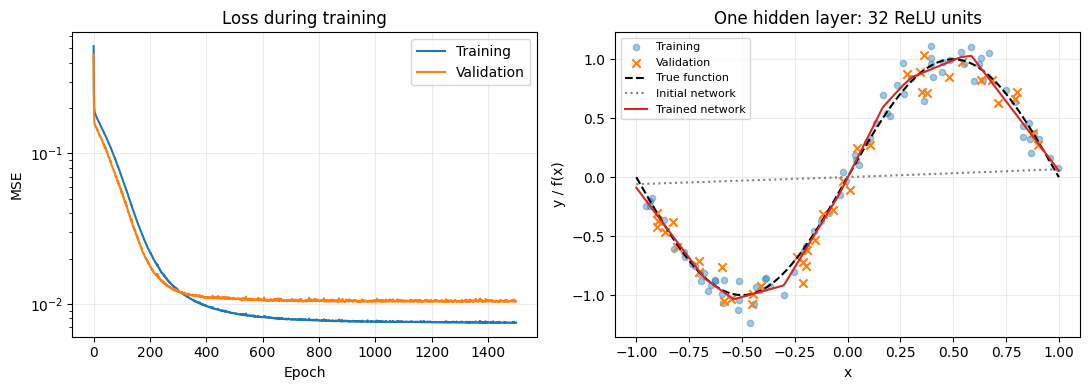

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.plot(train_history, label="Training")
ax.plot(val_history, label="Validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.set_yscale("log")
ax.set_title("Loss during training")
ax.legend()
ax.grid(alpha=0.25)

ax = axes[1]
ax.scatter(x_train[:, 0], y_train[:, 0], s=20, alpha=0.4, label="Training")
ax.scatter(x_val[:, 0], y_val[:, 0], marker="x", color="tab:orange", label="Validation")
ax.plot(x_grid[:, 0], y_true[:, 0], "k--", label="True function")
ax.plot(x_grid[:, 0], initial_prediction[:, 0], color="gray", linestyle=":", label="Initial network")
ax.plot(x_grid[:, 0], prediction[:, 0], color="tab:red", label="Trained network")
ax.set_xlabel("x")
ax.set_ylabel("y / f(x)")
ax.set_title(f"One hidden layer: {M} ReLU units")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### How does the fitted curve change?

Each panel uses the network parameters from the indicated epoch.

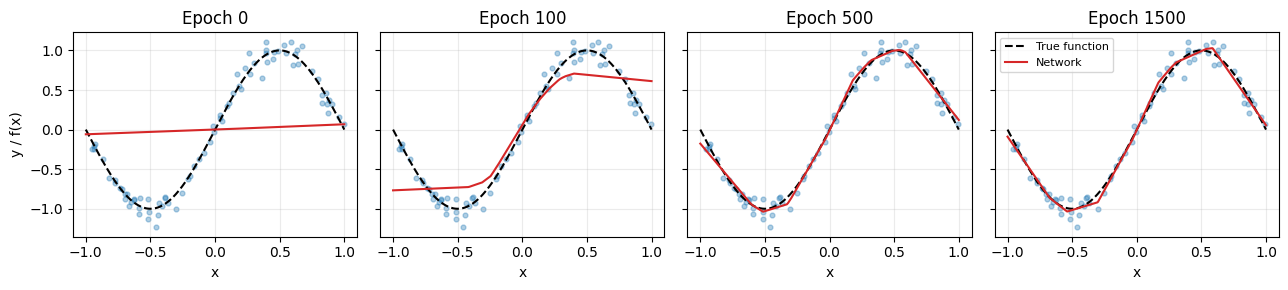

In [12]:
fig, axes = plt.subplots(1, len(snapshots), figsize=(13, 3), sharex=True, sharey=True)
for ax, (epoch, curve) in zip(axes, snapshots.items()):
    ax.scatter(x_train[:, 0], y_train[:, 0], s=12, alpha=0.35)
    ax.plot(x_grid[:, 0], y_true[:, 0], "k--", label="True function")
    ax.plot(x_grid[:, 0], curve[:, 0], color="tab:red", label="Network")
    ax.set_title(f"Epoch {epoch}")
    ax.set_xlabel("x")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("y / f(x)")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### What do the hidden units contribute?

Show four units with the largest variation in $w_j^{(2)}h_j(x)$ over the plotting grid. The output sums **all 32 contributions** and adds $b^{(2)}$.

ReLU features are piecewise linear. Their weighted sum can approximate a curved function.

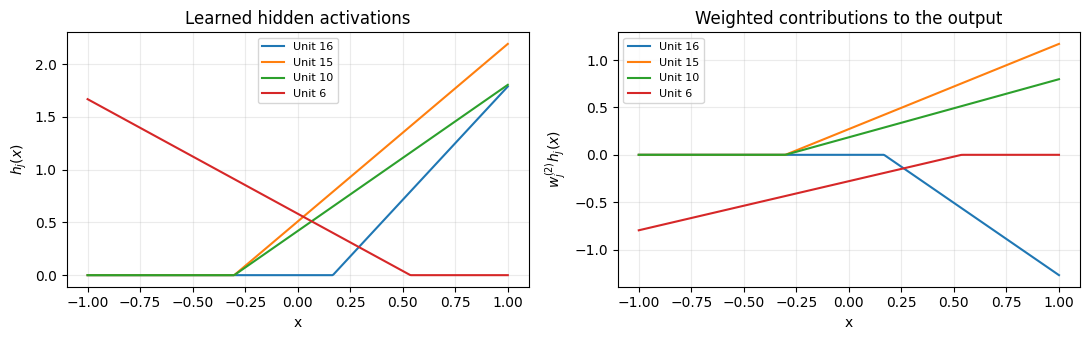

In [13]:
# Select four visibly influential units for illustration.
selected = contributions.std(dim=0).topk(4).indices.tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for j in selected:
    line, = axes[0].plot(x_grid[:, 0], hidden[:, j], label=f"Unit {j + 1}")
    axes[1].plot(x_grid[:, 0], contributions[:, j], color=line.get_color(),
                 label=f"Unit {j + 1}")
axes[0].set_title("Learned hidden activations")
axes[0].set_ylabel(r"$h_j(x)$")
axes[1].set_title("Weighted contributions to the output")
axes[1].set_ylabel(r"$w_j^{(2)}h_j(x)$")
for ax in axes:
    ax.set_xlabel("x")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Try:** Change `M` to 4 or 8, then rerun from the model cell. How does the fitted curve change?

**Question:** If `torch.relu(...)` is replaced by its input, what kind of function can the network represent?

## 6. The same network with `torch.nn`

The earlier implementation already uses PyTorch tensors and automatic differentiation. Now use its model and optimizer interfaces:

| Explicit implementation | PyTorch interface |
|---|---|
| `x @ w1 + b1` | `nn.Linear(1, M)` |
| `torch.relu(...)` | `nn.ReLU()` |
| `h @ w2 + b2` | `nn.Linear(M, 1)` |
| Mean squared error | `nn.MSELoss()` |
| Manual gradient updates | `torch.optim.SGD` |
| Clear each `.grad` | `optimizer.zero_grad()` |

`nn.Linear` stores weights as **(output features, input features)** and computes $XW^\top+b$. Transpose our weights when copying them.

Use the same data, initial parameters, batch order, learning rate, and epochs to compare the implementations.

In [14]:
import torch.nn as nn

# ============================================================
# 6.1 Model
# ============================================================
model = nn.Sequential(
    nn.Linear(1, M),
    nn.ReLU(),
    nn.Linear(M, 1),
)

# Match the explicit implementation's initial parameters.
with torch.no_grad():
    model[0].weight.copy_(initial_parameters[0].T)
    model[0].bias.copy_(initial_parameters[1])
    model[2].weight.copy_(initial_parameters[2].T)
    model[2].bias.copy_(initial_parameters[3])
    nn_initial_prediction = model(x_grid).clone()

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

# Restore the shuffle state from immediately before explicit training.
nn_generator = torch.Generator()
nn_generator.set_state(manual_shuffle_state)
nn_train_loader = DataLoader(
    TensorDataset(x_train, y_train), batch_size=batch_size,
    shuffle=True, generator=nn_generator,
)

print(model)
print(f"Initial predictions match: "
      f"{torch.allclose(nn_initial_prediction, initial_prediction, atol=1e-6)}")

Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
)
Initial predictions match: True


### Training

`model(x_batch)` performs the forward pass. The optimizer updates every parameter registered in the model.

In [15]:
# ============================================================
# 6.2 Training with an optimizer
# ============================================================
with torch.no_grad():
    nn_train_history = [criterion(model(x_train), y_train).item()]
    nn_val_history = [criterion(model(x_val), y_val).item()]

for epoch in range(1, num_epochs + 1):
    model.train()
    for x_batch, y_batch in nn_train_loader:
        optimizer.zero_grad()        # Clear previous gradients.
        outputs = model(x_batch)     # Forward pass.
        loss = criterion(outputs, y_batch)
        loss.backward()             # Automatic differentiation.
        optimizer.step()            # Gradient descent update.

    model.eval()
    with torch.no_grad():
        nn_train_history.append(criterion(model(x_train), y_train).item())
        nn_val_history.append(criterion(model(x_val), y_val).item())

    if epoch == 1 or epoch % print_every == 0 or epoch == num_epochs:
        print(f"Epoch {epoch:4d}: training MSE = {nn_train_history[-1]:.6f}, "
              f"validation MSE = {nn_val_history[-1]:.6f}")

Epoch    1: training MSE = 0.262720, validation MSE = 0.218767
Epoch  100: training MSE = 0.069403, validation MSE = 0.054562
Epoch  200: training MSE = 0.022042, validation MSE = 0.017759
Epoch  300: training MSE = 0.012270, validation MSE = 0.012006
Epoch  400: training MSE = 0.009658, validation MSE = 0.011031
Epoch  500: training MSE = 0.008632, validation MSE = 0.010792
Epoch  600: training MSE = 0.008133, validation MSE = 0.010635
Epoch  700: training MSE = 0.007884, validation MSE = 0.010446
Epoch  800: training MSE = 0.007749, validation MSE = 0.010431
Epoch  900: training MSE = 0.007644, validation MSE = 0.010469
Epoch 1000: training MSE = 0.007653, validation MSE = 0.010334
Epoch 1100: training MSE = 0.007618, validation MSE = 0.010325
Epoch 1200: training MSE = 0.007561, validation MSE = 0.010493
Epoch 1300: training MSE = 0.007515, validation MSE = 0.010473
Epoch 1400: training MSE = 0.007560, validation MSE = 0.010614
Epoch 1500: training MSE = 0.007493, validation MSE = 0

### Evaluation and comparison

Both versions implement the same network and SGD updates. Small numerical differences can arise from floating-point operations.

`model.eval()` sets evaluation behavior for layers that need it; `torch.no_grad()` disables gradient recording. This network has no dropout or batch normalization.

Implementation         Training MSE   Validation MSE
Explicit parameters        0.007492         0.010391
torch.nn + SGD             0.007493         0.010391


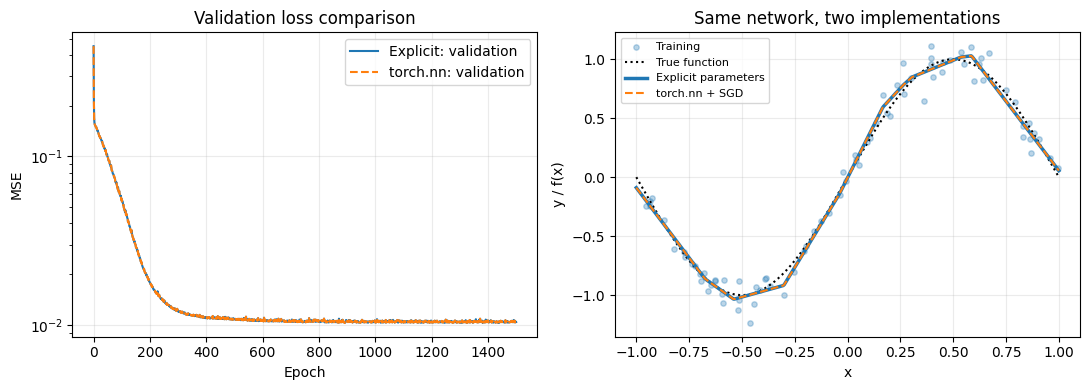

In [16]:
model.eval()
with torch.no_grad():
    nn_prediction = model(x_grid)
    nn_train_mse = criterion(model(x_train), y_train).item()
    nn_val_mse = criterion(model(x_val), y_val).item()

print(f"{'Implementation':<20} {'Training MSE':>14} {'Validation MSE':>16}")
print(f"{'Explicit parameters':<20} {train_mse:14.6f} {val_mse:16.6f}")
print(f"{'torch.nn + SGD':<20} {nn_train_mse:14.6f} {nn_val_mse:16.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(val_history, label="Explicit: validation")
ax.plot(nn_val_history, "--", label="torch.nn: validation")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.set_title("Validation loss comparison")
ax.legend()
ax.grid(alpha=0.25)

ax = axes[1]
ax.scatter(x_train[:, 0], y_train[:, 0], s=15, alpha=0.3, label="Training")
ax.plot(x_grid[:, 0], y_true[:, 0], "k:", label="True function")
ax.plot(x_grid[:, 0], prediction[:, 0], label="Explicit parameters", linewidth=2.5)
ax.plot(x_grid[:, 0], nn_prediction[:, 0], "--", label="torch.nn + SGD")
ax.set_xlabel("x")
ax.set_ylabel("y / f(x)")
ax.set_title("Same network, two implementations")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## backward computation using backward()

In [17]:
# Clear previous gradients.
optimizer.zero_grad()

# Forward pass and automatic differentiation.
outputs = model(x_train)
loss = criterion(outputs, y_train)
loss.backward()

# Inspect gradients.
for name, parameter in model.named_parameters():
    print(f"\n{name}: shape = {tuple(parameter.shape)}")
    print(parameter.grad)


0.weight: shape = (32, 1)
tensor([[-4.5036e-04],
        [-2.2199e-03],
        [ 2.0079e-04],
        [ 1.1745e-03],
        [ 4.7295e-04],
        [ 1.8966e-03],
        [-2.4357e-04],
        [ 7.2562e-04],
        [ 8.3662e-04],
        [-1.0765e-03],
        [ 9.9501e-04],
        [-1.3026e-03],
        [-1.2397e-03],
        [ 8.8382e-04],
        [-1.2996e-03],
        [ 2.1102e-03],
        [ 9.0549e-04],
        [ 1.0904e-03],
        [ 8.5319e-04],
        [-1.4061e-03],
        [-9.9105e-04],
        [ 1.2160e-03],
        [ 3.4548e-05],
        [ 1.9749e-03],
        [ 1.0406e-03],
        [-6.3390e-04],
        [ 1.1298e-03],
        [ 1.5046e-03],
        [-2.8516e-03],
        [-5.8668e-05],
        [ 1.4532e-03],
        [ 8.6191e-05]])

0.bias: shape = (32,)
tensor([ 6.7189e-04,  3.6089e-03, -4.5198e-04, -5.2476e-04,  6.9758e-04,
        -1.0802e-03,  3.9598e-04, -3.2421e-04, -3.7381e-04, -2.5772e-03,
         1.2994e-03,  1.9522e-03,  1.8579e-03, -8.7585e-04, -3.1112